# Robustness of Value Signals and Asset-Pricing Models in China A-Shares

## Research question
How robust is the evidence for A-share value signals when moving from corrected measurement to return prediction and model pricing? EP is the focal example, with five additional characteristics supplying a fixed comparison set.

## Research thread
1. **Measurement:** establish a common formation-time panel before interpreting any predictive result.
2. **Signal robustness:** distinguish EP rank association, conditional FM slopes and raw portfolio spreads; use the six-signal family to examine how broadly the conclusions hold under the same inference protocol.
3. **Complementary model pricing:** ask how CAPM and adapted FF3/FF5 price 25 common size-value portfolios. These are not the six signal spreads, so this is not a direct factor attribution of EP performance.

The liquidity snapshot and CAPM beta exercise are supporting diagnostics. The main contribution is a reproducible account of where value evidence holds and where it depends on measurement, controls or evaluation criteria, not a search for the best trading strategy.

## Findings at a glance
- 2005–2024 data: 5,647 observed securities and 623,062 eligible stock-months with observed forward returns.
- Conditional EP regression significance does not establish portfolio profitability: the raw spread has HAC p=0.072, BH q=0.108 and a seven-month-block Sharpe interval of [-0.03, 0.68].
- All six signals receive FM regressions and block Bootstrap. Seven-month-block Sharpe intervals are above zero for Size, Value and LowVol in the full sample; only Size and LowVol remain above zero in the retrospective holdout. Intervals are pointwise, and Profitability retains 29 internal missing calendar months.
- On 25 test portfolios over 174 common months, adapted FF5 does not uniformly dominate FF3.

## Reproduction and interpretation
Run all cells in order, or run `python run_research.py --data-dir PATH_TO_LICENSED_PARQUET_DIRECTORY` from the project root. Interactive use requires `ASHARE_DATA_DIR` to point to the authorized local inputs documented in [data.md](../docs/data.md).

One shared setup and panel feed the three sections below: data integrity, signal robustness, and asset-pricing comparison. Security-level intermediate panels remain in ignored `.local/` storage.

The chronological holdout is retrospective; industry classifications are static, vendor vintages may be incomplete, and gross academic spreads do not incorporate trading costs, borrowing or missing delisting proceeds. See [methodology](../docs/methodology.md).


In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from ashare_research import *
for folder in ['.local', 'results', 'figures']:
    (ROOT / folder).mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .2})

from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')


## 1. Data integrity and the investable universe

### Findings at a glance

The executed panel contains **623,062** usable eligible stock-months across **5,647** observed securities. **26,235** adjusted monthly returns differ from raw-close ratios by more than one percentage point; **401** forward labels remain missing. These are data-audit counts, not trading outcomes.

The analysis builds one common 2005–2024 monthly panel for signal-robustness tests and asset-pricing model comparison. Raw vendor data and intermediate stock-level panels remain local.

### Context & methods

Signals are observable at month-end **t** and evaluated against adjusted returns in **t+1**. Eligibility uses information at formation: historical ST status, at least 120 calendar days since listing, at least 15 active trading days (or all market trading days in shorter months), and trading on the formation date. Delisted companies are retained when present in the supplied exports.

#### Key assumptions

Announcement dates have no intraday timestamps, so reports announced on the formation date are conservatively unavailable. Financial versions are selected as of each formation date; same-day conflicting versions are unusable. The stored industry labels are static, so industry controls are a sensitivity analysis rather than a fully historical sector model. Missing next-month/delisting returns are counted, not imputed as successful exits.

### Data

Set `ASHARE_DATA_DIR` to your licensed Tushare-format Parquet directory, or use `run_research.py --data-dir ...`. No API key or data download is required at execution time.

#### Load, align, and validate the common panel

In [2]:
monthly, panel, audit = prepare_panel()
monthly.to_parquet(ROOT / '.local/monthly.parquet', index=False)
panel.to_parquet(ROOT / '.local/panel.parquet', index=False)
(ROOT / 'results/data_audit.json').write_text(json.dumps(audit, indent=2) + '\n', encoding='utf-8')
display(pd.Series(audit, name='Observed count').to_frame())
assert not monthly.duplicated(['ts_code', 'ym']).any()
assert panel['return_month'].max() <= pd.Period('2024-12', freq='M')
assert panel['trade_date'].lt(panel['return_month'].dt.to_timestamp()).all()


,Observed count
raw_stock_months,699093
stocks,5647
delisted_stocks_observed,310
adjustment_changes_over_1pp,26235
historical_st_stock_months,25688
income_conflicting_report_dates,6
balance_conflicting_report_dates,5
eligible_stock_months,623463
missing_forward_returns,401
usable_stock_months,623062


### Results
#### Coverage and missing forward labels

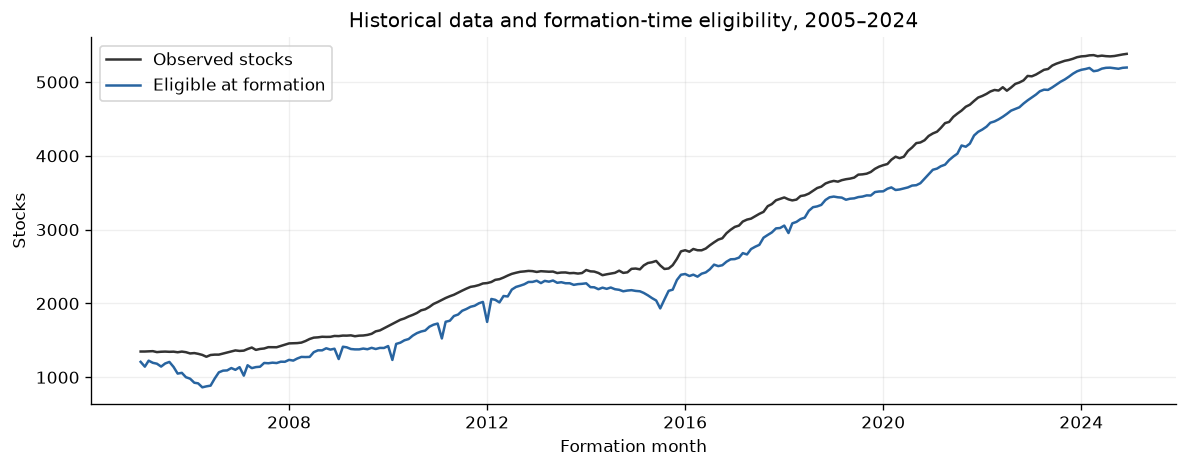

,raw_stocks,eligible_stocks,usable_forward_returns
ym,,,
2005-01,1349,1209,1209.0
2024-12,5381,5196,NaN


In [3]:
coverage = monthly.groupby('ym').agg(raw_stocks=('ts_code', 'size'), eligible_stocks=('eligible', 'sum'))
usable = panel.loc[panel['ret_next'].notna()].groupby('ym').size()
coverage['usable_forward_returns'] = usable
assert coverage['eligible_stocks'].gt(0).all(), 'A calendar rule emptied a market month'
coverage.to_csv(ROOT / 'results/monthly_coverage.csv')
fig, ax = plt.subplots(figsize=(10, 4))
for col, label, color in [('raw_stocks', 'Observed stocks', '#333333'), ('eligible_stocks', 'Eligible at formation', '#2864a0')]:
    ax.plot(coverage.index.to_timestamp(), coverage[col], label=label, color=color)
ax.set(ylabel='Stocks', xlabel='Formation month', title='Historical data and formation-time eligibility, 2005–2024')
ax.legend()
fig.tight_layout()
fig.savefig(ROOT / 'figures/universe_coverage.png')
plt.show()
display(coverage.iloc[[0, -1]])


#### Liquidity threshold sensitivity at the final study snapshot
This supporting diagnostic describes the final universe; it does not select the historical signal universe. The recent amount window uses the last 20 market trading dates. Amount is converted from thousand CNY to CNY. Missing trading dates are not treated as zero.

,threshold_cny,stocks,market_cap_coverage
0,1000000.0,5196,0.989006
1,5000000.0,5196,0.989006
2,10000000.0,5194,0.988963
3,20000000.0,5116,0.987346
4,50000000.0,4460,0.965422
5,100000000.0,3329,0.908034


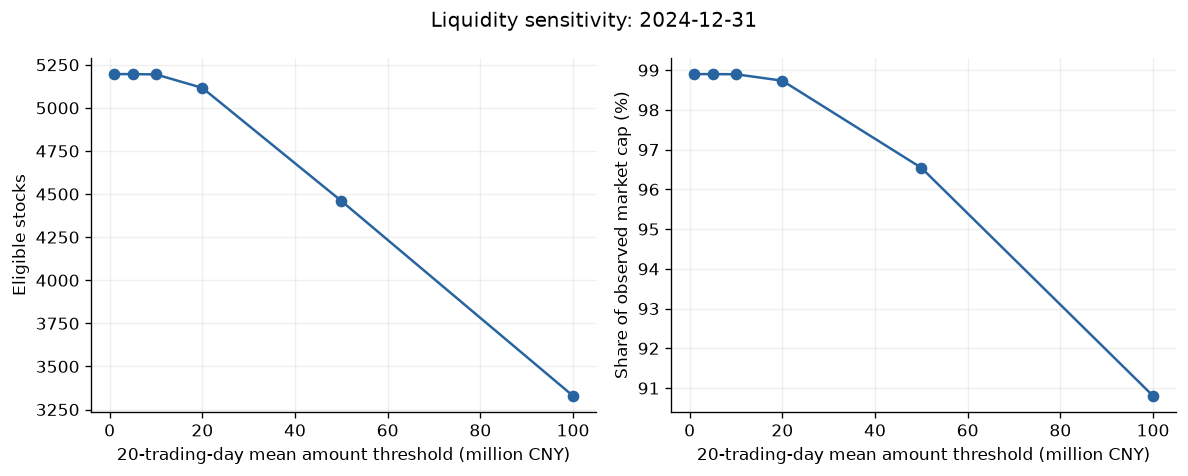

In [4]:
snapshot = monthly.loc[monthly['ym'] == monthly['ym'].max()].copy()
base = snapshot.loc[snapshot['eligible']]
total_cap = snapshot['mktcap'].sum()
liquidity = pd.DataFrame([{'threshold_cny': threshold,
    'stocks': int((base['avg_amount_20d'] >= threshold).sum()),
    'market_cap_coverage': base.loc[base['avg_amount_20d'] >= threshold, 'mktcap'].sum()/total_cap}
    for threshold in [1e6, 5e6, 1e7, 2e7, 5e7, 1e8]])
liquidity.to_csv(ROOT / 'results/liquidity_sensitivity.csv', index=False)
display(liquidity)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(liquidity['threshold_cny']/1e6, liquidity['stocks'], 'o-', color='#2864a0')
axes[1].plot(liquidity['threshold_cny']/1e6, liquidity['market_cap_coverage']*100, 'o-', color='#2864a0')
for ax in axes:
    ax.set_xlabel('20-trading-day mean amount threshold (million CNY)')
axes[0].set_ylabel('Eligible stocks')
axes[1].set_ylabel('Share of observed market cap (%)')
fig.suptitle(f'Liquidity sensitivity: {snapshot["trade_date"].max():%Y-%m-%d}')
fig.tight_layout()
fig.savefig(ROOT / 'figures/liquidity_sensitivity.png')
plt.show()


### Takeaways
The saved audit measures how many return observations change after adjustment, the historical ST exclusions, ambiguous report versions, and missing future labels. The snapshot analysis is descriptive and does not establish a predictive signal. Raw returns are not winsorized in the primary analysis; the research does not assume that realized extreme losses could have been clipped away.

## 2. Signal robustness: EP as the main case, six signals as comparison

The common panel now fixes the return labels and formation-time universe. We next ask whether predictive evidence remains after accounting for exposures, dependence and multiple testing. EP is examined in detail because its IC, controlled slope and raw spread give different answers; applying the same tests to the other five signals avoids presenting EP in isolation.

### Findings at a glance

EP-only, size-controlled, and size/static-industry-controlled FM HAC t statistics are **1.25, 3.90, and 7.04**. The gross EP quintile spread has Sharpe **0.32**, BH q **0.108**, and seven-month-block 95% Sharpe CI **[-0.03, 0.68]**. Its retrospective holdout HAC p is **0.336**. Conditional significance does not establish robust raw portfolio profitability.

### Context & methods

**Question:** Do the six declared signals predict next-month returns, and how do exposure controls, time-series inference and a chronological split change the evidence?

All six signals receive monthly Fama–MacBeth regressions and raw/neutralized Rank IC tests. Characteristics are winsorized at 1%/99%, standardized and oriented toward the declared long side; Size uses negative standardized log market capitalization and LowVol reverses standardized volatility. Each signal uses its own available sample, held fixed across specifications. The five non-Size signals have raw, size-controlled and size/static-industry-controlled regressions. Size has raw and static-industry-controlled regressions: controlling size by itself would be collinear. Newey–West inference uses six calendar-month lags. BH/Holm corrections are applied within each period and statistic (six tests, except the five size-controlled slopes). These corrections are not global over all research choices. Static industry controls remain a sensitivity analysis.

Six real signals form one declared multiple-testing family: EP, size, value (inverse PB), momentum, low total volatility, and the available annual operating-profitability proxy. Each signal uses available observations in the same formation-time universe; its portfolio is equal-weighted top-minus-bottom quintiles with the declared direction. Negative results remain negative. The strategy series are gross academic spreads, with 100% long and 100% short exposure, before fees, borrowing constraints, or execution costs.

The 2018–2024 period is a **retrospective chronological holdout**, defined after the full sample had already been examined. It is not an untouched prospective test. No hyperparameter is selected from its returns.

### Data

#### Fama–MacBeth coefficients and Rank IC

In [5]:
fm_monthly, fm_rows = [], []
for name in SIGNALS:
    prepared, signal_coefficients, summary = fama_macbeth(panel, name)
    fm_monthly.append(signal_coefficients.assign(signal=name).reset_index())
    fm_rows.append(summary)
    if name == 'EP':
        ep_panel = prepared
        coefficients = signal_coefficients.rename(columns={'Signal': 'EP', 'Size_controlled': 'EP_Size', 'Industry_controlled': 'EP_Size_Industry'})
fm_monthly = pd.concat(fm_monthly, ignore_index=True)
fm_summary = pd.concat(fm_rows, ignore_index=True)
for _, indices in fm_summary.groupby(['period', 'specification']).groups.items():
    pvalues = fm_summary.loc[indices, 'p_hac']
    fm_summary.loc[indices, 'q_bh'] = multipletests(pvalues, method='fdr_bh')[1]
    fm_summary.loc[indices, 'p_holm'] = multipletests(pvalues, method='holm')[1]
    fm_summary.loc[indices, 'family_tests'] = len(indices)
fm_monthly.to_csv(ROOT / 'results/fm_monthly_statistics.csv', index=False)
fm_summary.to_csv(ROOT / 'results/fm_inference.csv', index=False)
ep_summary = fm_summary.loc[fm_summary['signal'] == 'EP'].copy()
ep_summary['specification'] = ep_summary['specification'].replace({'Signal': 'EP', 'Size_controlled': 'EP_Size', 'Industry_controlled': 'EP_Size_Industry'})
coefficients.to_csv(ROOT / 'results/ep_monthly_statistics.csv')
ep_summary.to_csv(ROOT / 'results/ep_inference.csv', index=False)
assert set(fm_summary['signal']) == set(SIGNALS)
assert not fm_summary.query("signal == 'Size'")['specification'].eq('Size_controlled').any()
display(fm_summary.query("period == 'Full' and specification in ['Signal', 'Industry_controlled']")[['signal', 'specification', 'months', 'mean', 't_hac', 'p_hac', 'q_bh']].round(6))


,signal,specification,months,mean,t_hac,p_hac,q_bh
0,EP,Signal,239,0.001155,1.248135,0.211982,0.299361
1,EP,Industry_controlled,239,0.004411,7.035699,0.000000,0.000000
15,Size,Signal,239,0.004896,3.639914,0.000273,0.000818
16,Size,Industry_controlled,239,0.005296,3.859136,0.000114,0.000171
27,Value,Signal,239,0.002587,2.557000,0.010558,0.021116
28,Value,Industry_controlled,239,0.003894,5.510703,0.000000,0.000000
42,Momentum,Signal,227,-0.001137,-1.151644,0.249467,0.299361
43,Momentum,Industry_controlled,227,-0.000731,-0.971789,0.331155,0.331155
57,LowVol,Signal,239,0.003109,3.798533,0.000146,0.000818
58,LowVol,Industry_controlled,239,0.004359,7.098126,0.000000,0.000000


### Results
#### Controlled coefficient estimates with 95% HAC intervals

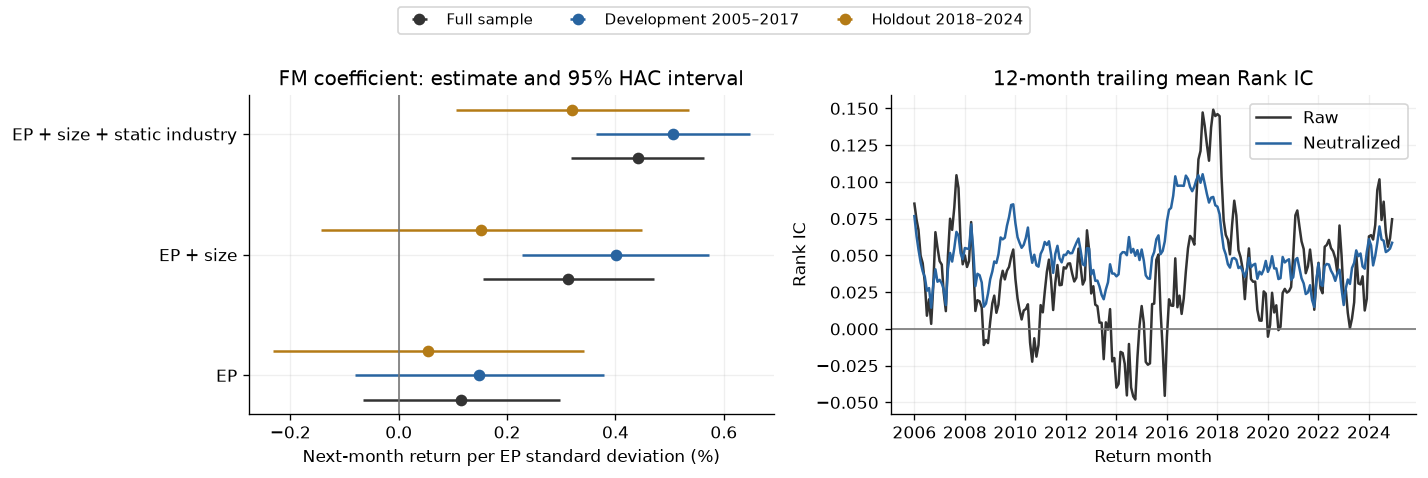

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
periods = ['Full', 'Development_2005_2017', 'Holdout_2018_2024']
colors = ['#333333', '#2864a0', '#b47b16']
for offset, period, color in zip([-.2, 0, .2], periods, colors):
    selected = ep_summary.loc[(ep_summary['period'] == period) & ep_summary['specification'].isin(['EP', 'EP_Size', 'EP_Size_Industry'])]
    selected = selected.set_index('specification').loc[['EP', 'EP_Size', 'EP_Size_Industry']]
    axes[0].errorbar(selected['mean']*100, np.arange(3)+offset,
                    xerr=1.96*selected['se_hac']*100, fmt='o', color=color, label=period)
axes[0].axvline(0, color='#777777', lw=1)
axes[0].set_yticks(range(3), ['EP', 'EP + size', 'EP + size + static industry'])
axes[0].set_xlabel('Next-month return per EP standard deviation (%)')
axes[0].set_title('FM coefficient: estimate and 95% HAC interval')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, ['Full sample', 'Development 2005–2017', 'Holdout 2018–2024'], loc='upper center', ncol=3, fontsize=9)
for col, label, color in [('raw_ic', 'Raw', '#333333'), ('neutral_ic', 'Neutralized', '#2864a0')]:
    axes[1].plot(coefficients.index.to_timestamp(), coefficients[col].rolling(12).mean(), label=label, color=color)
axes[1].axhline(0, color='#777777', lw=1)
axes[1].set(xlabel='Return month', ylabel='Rank IC', title='12-month trailing mean Rank IC')
axes[1].legend()
fig.tight_layout(rect=(0, 0, 1, .90))
fig.savefig(ROOT / 'figures/ep_robustness.png')
plt.show()


#### Six-signal regression comparison
Controlled means size plus static industry for five signals, and static industry only for Size. Positive slopes align with the declared signal direction. Pointwise intervals are not multiple-testing-adjusted; use the saved BH/Holm columns for family-level inference. Available samples differ across signals.

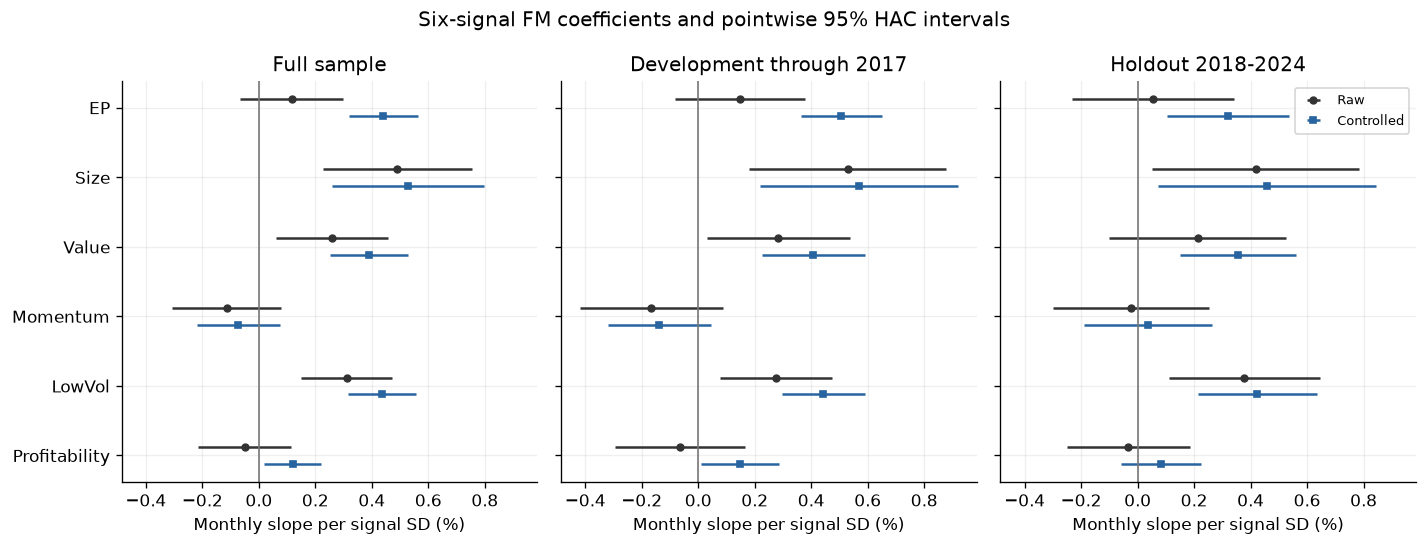

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.6), sharex=True, sharey=True)
for ax, period, title in zip(axes, periods, ['Full sample', 'Development through 2017', 'Holdout 2018-2024']):
    for offset, specification, label, color, marker in [(-.12, 'Signal', 'Raw', '#333333', 'o'), (.12, 'Industry_controlled', 'Controlled', '#2864a0', 's')]:
        selected = fm_summary.query('period == @period and specification == @specification').set_index('signal').loc[list(SIGNALS)]
        ax.errorbar(selected['mean']*100, np.arange(6)+offset, xerr=1.96*selected['se_hac']*100, fmt=marker, color=color, label=label, markersize=4)
    ax.axvline(0, color='#777777', lw=1)
    ax.set(yticks=range(6), yticklabels=list(SIGNALS), xlabel='Monthly slope per signal SD (%)', title=title)
axes[0].invert_yaxis()
axes[-1].legend(fontsize=8)
fig.suptitle('Six-signal FM coefficients and pointwise 95% HAC intervals')
fig.tight_layout()
fig.savefig(ROOT / 'figures/signal_fm_comparison.png')
plt.show()


#### Six observed signals, with BH-FDR and Holm correction
Adjusted p values come from real HAC tests of these six portfolio return series. They do not mix real results with simulated p values.

,months,mean,t_hac,p_hac,se_hac,period,signal,ann_mean,sharpe,q_bh,p_holm
0,239,0.004352,1.800844,0.071727,0.002417,Full,EP,0.052227,0.321259,0.107591,0.215182
1,239,0.016052,4.152678,0.000033,0.003866,Full,Size,0.192630,0.913324,0.000197,0.000197
2,239,0.008689,2.982599,0.002858,0.002913,Full,Value,0.104266,0.579462,0.005716,0.011432
3,227,-0.001597,-0.582834,0.560005,0.002741,Full,Momentum,-0.019169,-0.118611,0.560005,0.932887
4,239,0.007698,3.346427,0.000819,0.002300,Full,LowVol,0.092372,0.540347,0.002456,0.004093
5,160,-0.001757,-0.728278,0.466443,0.002412,Full,Profitability,-0.021078,-0.195898,0.559732,0.932887
6,155,0.004588,1.537604,0.124145,0.002984,Development_2005_2017,EP,0.055051,0.331106,0.186218,0.372436
7,155,0.017070,3.300874,0.000964,0.005171,Development_2005_2017,Size,0.204845,0.925056,0.005783,0.005783
8,155,0.008916,2.484666,0.012967,0.003588,Development_2005_2017,Value,0.106989,0.579458,0.027465,0.064837
9,143,-0.003127,-0.845386,0.397895,0.003699,Development_2005_2017,Momentum,-0.037526,-0.223328,0.418438,0.795791


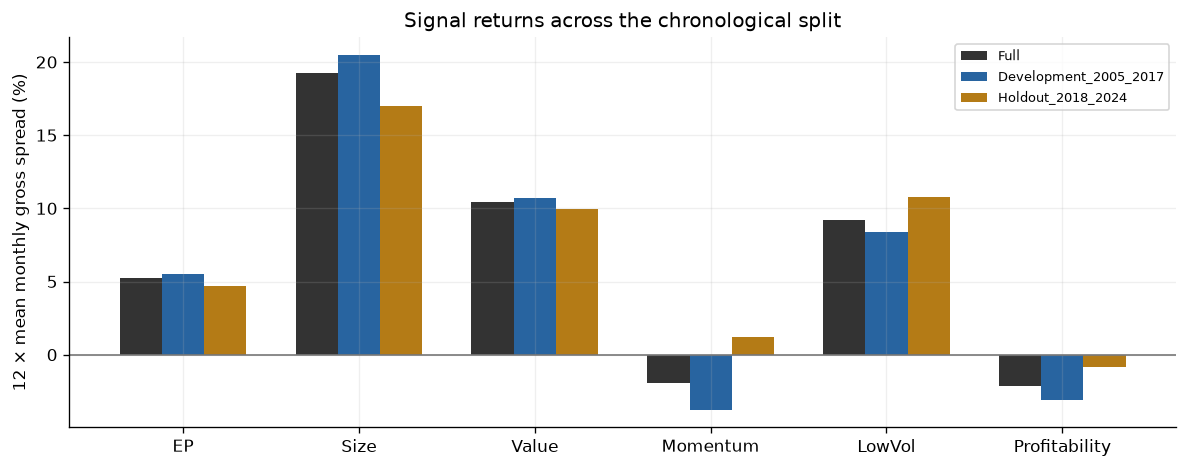

In [8]:
portfolios, spreads, signal_summary = signal_tests(panel)
spreads.to_csv(ROOT / 'results/signal_spreads.csv')
signal_summary.to_csv(ROOT / 'results/signal_inference.csv', index=False)
for name, frame in portfolios.items():
    frame.to_csv(ROOT / f'results/quintiles_{name.lower()}.csv')
display(signal_summary.round(6))
fig, ax = plt.subplots(figsize=(10, 4))
for offset, period, color in zip([-.24, 0, .24], periods, colors):
    values = signal_summary.loc[signal_summary['period'] == period].set_index('signal').loc[list(SIGNALS)]
    ax.bar(np.arange(6)+offset, values['ann_mean']*100, width=.24, label=period, color=color)
ax.axhline(0, color='#777777', lw=1)
ax.set_xticks(range(6), list(SIGNALS))
ax.set(ylabel='12 × mean monthly gross spread (%)', title='Signal returns across the chronological split')
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(ROOT / 'figures/signal_period_comparison.png')
plt.show()


#### Block Bootstrap for all six signal Sharpes
10,000 moving-block resamples per signal, period and block length (3, 6, 7, 12 calendar months); pointwise 95% percentile intervals, not simultaneous six-signal confidence bands. Full, development and retrospective holdout periods are all reported. Seven-month blocks are displayed, not selected for favorable results; the CSV retains all sensitivity settings.

Profitability has missing internal months. Blocks preserve those calendar positions; each sampled Sharpe uses its observed returns. This does not recover missing data or prove that missingness is random. Other signals have different start dates, so their full-sample estimates are not common-window rankings. These intervals describe gross long-short Sharpe, not FM coefficients or IC.

,period,signal,months,missing_months,sharpe,ci_low,ci_high
2,Full,EP,239,0,0.3213,-0.0257,0.6798
6,Full,Size,239,0,0.9133,0.4909,1.4159
10,Full,Value,239,0,0.5795,0.2035,0.9914
14,Full,Momentum,227,0,-0.1186,-0.5706,0.2833
18,Full,LowVol,239,0,0.5403,0.2302,0.9369
22,Full,Profitability,160,29,-0.1959,-0.6956,0.4044
26,Development_2005_2017,EP,155,0,0.3311,-0.1244,0.7200
30,Development_2005_2017,Size,155,0,0.9251,0.4637,1.6646
34,Development_2005_2017,Value,155,0,0.5795,0.1479,1.1205
38,Development_2005_2017,Momentum,143,0,-0.2233,-0.8998,0.2360


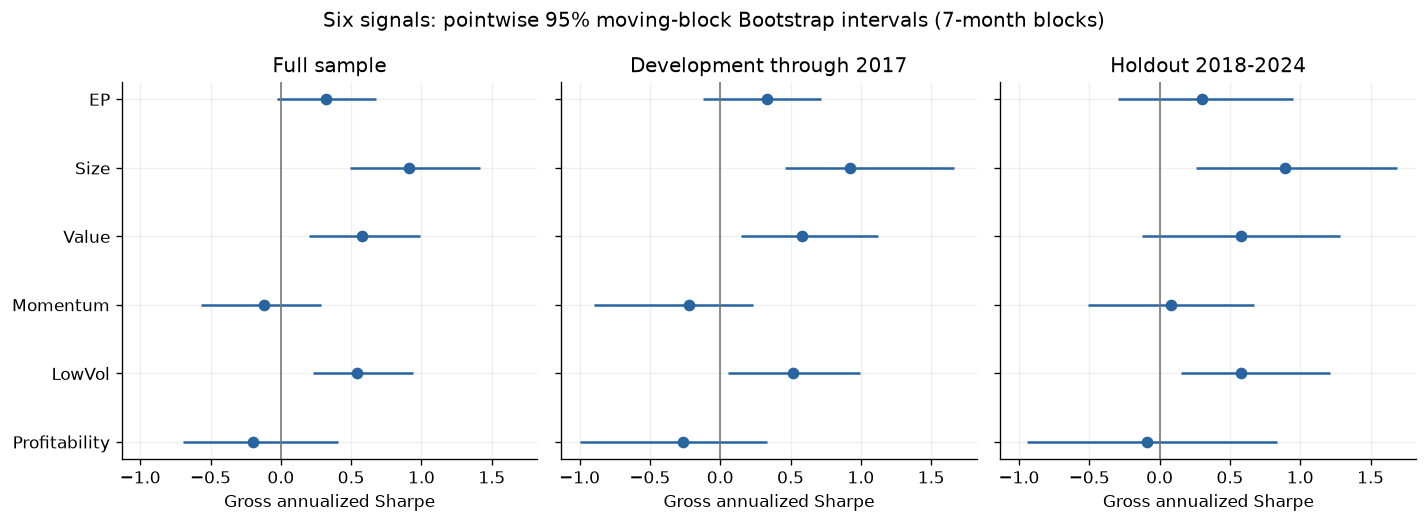

In [9]:
bootstrap_rows = []
for period, values in [('Full', spreads), ('Development_2005_2017', spreads.loc[spreads.index < HOLDOUT]), ('Holdout_2018_2024', spreads.loc[spreads.index >= HOLDOUT])]:
    for name in SIGNALS:
        for length in [3, 6, 7, 12]:
            bootstrap_rows.append({'period': period, 'signal': name, **block_bootstrap(values[name], block_length=length)})
bootstrap = pd.DataFrame(bootstrap_rows)
bootstrap.to_csv(ROOT / 'results/signal_bootstrap.csv', index=False)
bootstrap.query("signal == 'EP'").to_csv(ROOT / 'results/ep_bootstrap.csv', index=False)
assert len(bootstrap) == 6 * 3 * 4
assert np.isfinite(bootstrap[['sharpe', 'ci_low', 'ci_high']]).all().all()
display(bootstrap.query('block_length == 7')[['period', 'signal', 'months', 'missing_months', 'sharpe', 'ci_low', 'ci_high']].round(4))
fig, axes = plt.subplots(1, 3, figsize=(12, 4.4), sharex=True, sharey=True)
for ax, period, title in zip(axes, periods, ['Full sample', 'Development through 2017', 'Holdout 2018-2024']):
    selected = bootstrap.query('block_length == 7 and period == @period').set_index('signal').loc[list(SIGNALS)]
    ax.hlines(np.arange(6), selected['ci_low'], selected['ci_high'], color='#2864a0')
    ax.plot(selected['sharpe'], np.arange(6), 'o', color='#2864a0')
    ax.axvline(0, color='#777777', lw=1)
    ax.set(yticks=range(6), yticklabels=list(SIGNALS), xlabel='Gross annualized Sharpe', title=title)
axes[0].invert_yaxis()
fig.suptitle('Six signals: pointwise 95% moving-block Bootstrap intervals (7-month blocks)')
fig.tight_layout()
fig.savefig(ROOT / 'figures/signal_bootstrap.png')
plt.show()


#### Permutation diagnostic
2,000 permutations of ranked returns within each monthly cross-section. This diagnostic requires within-month exchangeability and does not preserve the temporal dependence of individual stocks. HAC inference and the chronological split remain the primary evidence.

In [10]:
permutation = permutation_ic(ep_panel)
(ROOT / 'results/ep_permutation.json').write_text(json.dumps(permutation, indent=2)+'\n', encoding='utf-8')
display(pd.Series(permutation).to_frame('Value'))


,Value
months,239.000000
repetitions,2000.000000
mean_ic,0.036644
p_exchangeability,0.000500


### Takeaways

In [11]:
full = signal_summary.query("period == 'Full' and signal == 'EP'").iloc[0]
hold = signal_summary.query("period == 'Holdout_2018_2024' and signal == 'EP'").iloc[0]
print(f"EP gross spread: full-sample HAC p={full.p_hac:.4g}, BH q={full.q_bh:.4g}; chronological-holdout HAC p={hold.p_hac:.4g}.")
print('Read FM coefficients, IC, and long-short Sharpe as different estimands. Conditional association is not a causal effect.')
print('A significant full-sample test does not establish an executable trading edge or validate every subperiod.')

print('Six-signal comparison: raw slopes, controlled slopes and spreads need not agree.')
for period in periods:
    for specification in ['Signal', 'Industry_controlled']:
        selected = fm_summary.query('period == @period and specification == @specification and q_bh < .05')
        print(period, specification, 'BH q<0.05:', ', '.join(selected['signal']) or 'none')
    selected = bootstrap.query('period == @period and block_length == 7 and ci_low > 0')
    print(period, 'positive pointwise Sharpe intervals:', ', '.join(selected['signal']) or 'none')


EP gross spread: full-sample HAC p=0.07173, BH q=0.1076; chronological-holdout HAC p=0.3365.
Read FM coefficients, IC, and long-short Sharpe as different estimands. Conditional association is not a causal effect.
A significant full-sample test does not establish an executable trading edge or validate every subperiod.
Six-signal comparison: raw slopes, controlled slopes and spreads need not agree.
Full Signal BH q<0.05: Size, Value, LowVol
Full Industry_controlled BH q<0.05: EP, Size, Value, LowVol, Profitability
Full positive pointwise Sharpe intervals: Size, Value, LowVol
Development_2005_2017 Signal BH q<0.05: Size, LowVol
Development_2005_2017 Industry_controlled BH q<0.05: EP, Size, Value, LowVol, Profitability
Development_2005_2017 positive pointwise Sharpe intervals: Size, Value, LowVol
Holdout_2018_2024 Signal BH q<0.05: LowVol
Holdout_2018_2024 Industry_controlled BH q<0.05: EP, Size, Value, LowVol
Holdout_2018_2024 positive pointwise Sharpe intervals: Size, LowVol


## 3. Complementary evidence: pricing size-value portfolios

The signal study establishes conditional and portfolio-level evidence, not a complete asset-pricing explanation. We therefore turn to the related question of joint pricing errors on 25 size-value portfolios. This uses the same data foundation but different test assets, formation rules and sample dates. It neither explains the six signal spreads directly nor validates a trading strategy.

### Findings at a glance

On **25** portfolios and **174** common months, GRS p values are **0.044 (CAPM), 0.120 (FF3), and 0.088 (FF5)**. CAPM is rejected at 5%; neither adaptation is rejected. FF5 has a smaller mean absolute alpha but a larger GRS statistic than FF3. These are in-sample pricing results under conventional GRS assumptions.

### Context & methods

Compare CAPM, an A-share FF3 adaptation, and an A-share FF5 adaptation on the **same 25 size–value portfolios and common months**.

Each June, form size and accounting-characteristic portfolios using only report versions available strictly before formation. Annual B/M uses prior-year book equity over prior-December market capitalization. Hold from July through the following June, with monthly value weights based on prior-month market capitalization. Returns of held stocks are read from the full observed price panel, not from next month's eligibility-filtered universe.

FF5 SMB averages SMB from size–value, size–profitability, and size–investment sorts. RMW uses an OP proxy because the supplied income schema has no interest-expense field. Breakpoints use the local A-share universe, not NYSE breakpoints. These are explicitly **adapted factors**, not official Fama–French series.

GRS uses the unbiased covariance convention and scaling in CRAN `GRS.test`; rejection is reported at a fixed 5% level. Failure to reject does not prove the model. The finite-sample F reference distribution has stronger assumptions than HAC inference and is interpreted accordingly.

The benchmark market premium is formation-time investable-universe value-weighted return less monthlyized one-year SHIBOR. Before SHIBOR is available, 3% annualized is a disclosed approximation; it is not the U.S. Treasury risk-free series.

### Data

#### Build adapted factors, common test assets, and GRS statistics

In [12]:
ff3, ff5, test_assets, grs, alphas, holding_coverage = asset_pricing(panel, monthly)
ff3.to_csv(ROOT / 'results/adapted_ff3.csv')
ff5.to_csv(ROOT / 'results/adapted_ff5.csv')
test_assets.to_csv(ROOT / 'results/test_portfolios_25.csv')
grs.to_csv(ROOT / 'results/grs_comparison.csv', index=False)
alphas.to_csv(ROOT / 'results/pricing_alphas.csv')
holding_coverage.to_csv(ROOT / 'results/annual_holding_coverage.csv')
display(grs.round(6))
assert grs['months'].nunique() == 1
assert grs['assets'].eq(25).all()
assert (grs['reject_5pct'] == (grs['p_value'] < .05)).all()


,months,assets,factors,grs,p_value,mean_abs_alpha,model,start,end,reject_5pct
0,174,25,1,1.605930,0.044336,0.003471,CAPM,2010-07,2024-12,True
1,174,25,3,1.386449,0.119692,0.001609,FF3_adapted,2010-07,2024-12,False
2,174,25,5,1.458456,0.088013,0.001481,FF5_adapted,2010-07,2024-12,False


### Results
#### Pricing errors on the common comparison sample

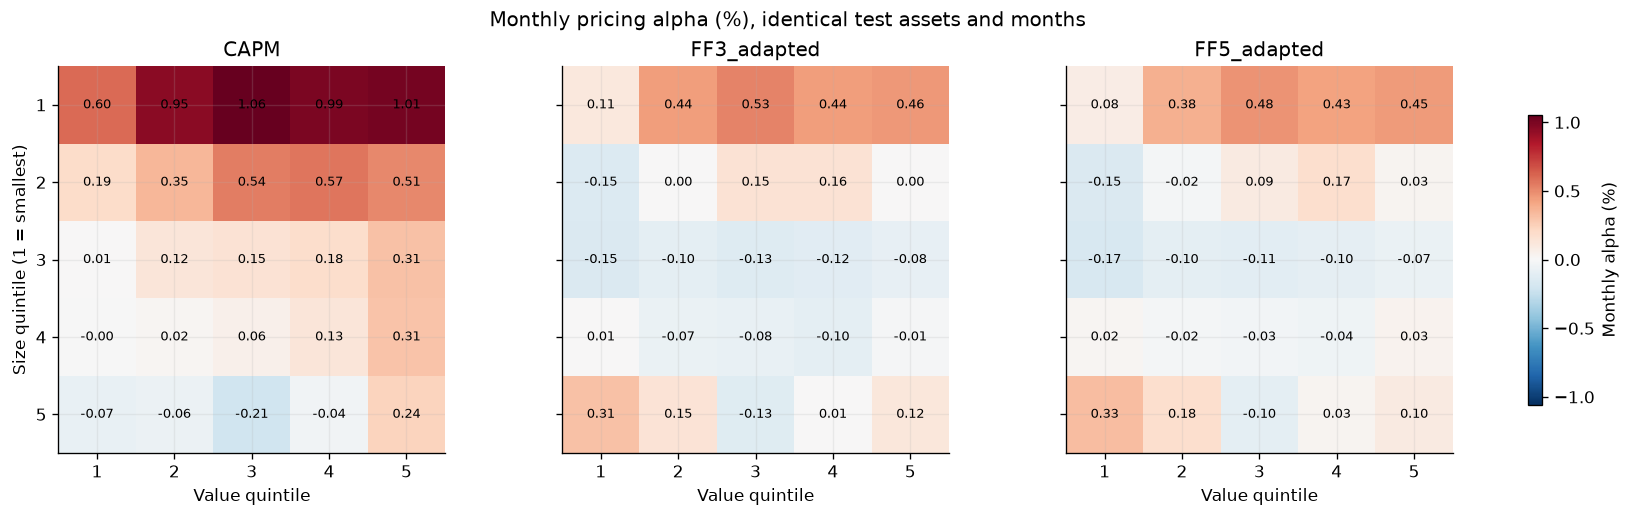

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharex=True, sharey=True, layout='constrained')
limit = np.abs(alphas.to_numpy()).max()*100
for ax, name in zip(axes, alphas.columns):
    image = ax.imshow(alphas[name].to_numpy().reshape(5, 5)*100, vmin=-limit, vmax=limit, cmap='RdBu_r')
    ax.set(xticks=range(5), yticks=range(5), xticklabels=range(1, 6), yticklabels=range(1, 6), xlabel='Value quintile', title=name)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, f'{alphas[name].iloc[i*5+j]*100:.2f}', ha='center', va='center', fontsize=8)
axes[0].set_ylabel('Size quintile (1 = smallest)')
fig.suptitle('Monthly pricing alpha (%), identical test assets and months')
fig.colorbar(image, ax=axes, shrink=.75, label='Monthly alpha (%)')
fig.savefig(ROOT / 'figures/pricing_alpha_comparison.png', bbox_inches='tight')
plt.show()


#### CAPM cross-sectional beta pricing
This supporting exercise distinguishes a price of estimated beta from the preceding joint time-series pricing test. Estimate each stock beta using the trailing 60 calendar months through formation, requiring at least 36 valid observations. Beta measured at month-end t predicts excess returns in t+1.

In [14]:
beta_coefficients, beta_summary = beta_pricing(monthly, panel)
beta_coefficients.to_csv(ROOT / 'results/beta_monthly_prices.csv', index=False)
beta_summary.to_csv(ROOT / 'results/beta_inference.csv', index=False)
display(beta_summary.round(6))


,specification,months,mean,t_hac,p_hac,se_hac
0,Beta,180,-0.005404,-2.093555,0.036300,0.002581
1,Beta_Size_Value,180,-0.004340,-1.917864,0.055128,0.002263


### Takeaways

In [15]:
for r in grs.itertuples():
    verdict = 'reject joint zero alpha' if r.reject_5pct else 'do not reject joint zero alpha'
    print(f'{r.model}: GRS={r.grs:.3f}, p={r.p_value:.4g}; {verdict} at 5%.')
print('Different model p values are not themselves a direct test of the improvement between nested models.')
print('Smaller in-sample pricing errors are not evidence of predictive outperformance or tradability.')
print('Missing holding returns and incomplete historical coverage remain data limitations; see the coverage CSV and README.')


CAPM: GRS=1.606, p=0.04434; reject joint zero alpha at 5%.
FF3_adapted: GRS=1.386, p=0.1197; do not reject joint zero alpha at 5%.
FF5_adapted: GRS=1.458, p=0.08801; do not reject joint zero alpha at 5%.
Different model p values are not themselves a direct test of the improvement between nested models.
Smaller in-sample pricing errors are not evidence of predictive outperformance or tradability.
Missing holding returns and incomplete historical coverage remain data limitations; see the coverage CSV and README.


## Overall conclusion

The measurement corrections matter before any financial interpretation. On that corrected panel, EP's conditional association can be significant while its gross spread remains inconclusive (BH q=0.108; seven-month-block 95% Sharpe interval [-0.03, 0.68]). The six-signal comparison shows that conclusions also depend on the statistic and period: in the retrospective holdout, only LowVol's raw FM slope survives its BH family, whereas only Size's portfolio spread survives the separate portfolio BH family. Positive pointwise Bootstrap intervals for Size and LowVol are not simultaneous multiple-testing-adjusted evidence.

The complementary pricing test finds mixed FF3/FF5 rankings on 25 size-value portfolios; it does not attribute EP spread returns to those models. Thus the study supports a narrower conclusion than robust value alpha or a universally superior pricing model: **value evidence is sensitive to measurement, conditioning and the question being tested.** Static industry labels, incomplete vendor vintages, missing returns and unmodeled trading costs remain limitations.
